# Batch 9: improving the results
One study of the improvements listed after the recheck (Batch 8):

1. **PINC learns its own constants**: wn, xi, mu (and th0) are trained together with the network, starting from the simulation fit.
2. **Physics weight**: 1 (as before) and 0.1 (data counts more).
3. **Ensemble**: the 5 seeds averaged at every step into one model.
4. **Inverse PINN on position, one fit per setpoint step** (no sudden jumps inside a fit).
5. **Better equations**: sin(theta) for pitch; cart friction and a level offset for Amr's x model.

Same design for every network (output = change per step, inputs state + command now + command one step ago + dt), same data and splits as before:

| Case | Train | Test | Equation |
|---|---|---|---|
| motors off | impulse_1-4 | impulse_5 | 1-DOF: theta'' = -2 xi wn q - wn^2 (theta - th0) + mu M(t - 0.02) |
| hover | doublet_1-4 (windows end before the motor kick-back) | doublet_5, doublet_6 | same 1-DOF equation |
| CL position | position_1, 3 | position_2 | Ghezzi: x'' = wn^2 (x_sp - x) - 2 xi wn v |

Scores: rollout VAF of the state (pitch or x), its rate, and its acceleration (speed differentiated, smoothed over 0.5 s); 5 seeds each.

## 0. Setup and data

In [1]:
import numpy as np, pandas as pd, torch, time, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.signal import savgol_filter
torch.set_num_threads(4)
DT = 0.02; SEEDS = [0, 1, 2, 3, 4]; EPOCHS = 10000
vaf = lambda y, yh: max(1 - np.var(y - yh) / np.var(y), 0) * 100
acc = lambda s: savgol_filter(s, 25, 2, deriv=1, delta=DT)          # smoothed derivative (0.5 s window)

def clean(kind, n, cols):                                           # Amr's clean files, every 5th row = 50 Hz
    f = pd.read_csv(f'../data/clean/{kind}/{n}.csv').iloc[::5].reset_index(drop=True)
    return pd.DataFrame(dict(t=f.t, y=f[cols[0]], yd=f[cols[1]], r=f[cols[2]]))

FL = pd.read_csv('../data/1dof/flights_1dof.csv').set_index('file')
def hover(n):                                                       # my windows: stop just before the motor kick-back
    r = FL.loc[n + '.csv']; df = pd.read_csv('../data/1dof/' + n + '.csv')
    after = df[df.t > r.inj_start_s + 0.7]
    end = after.t[after.M.abs() > 0.12].iloc[0] - 0.05
    f = df[(df.t >= r.inj_start_s - 0.1) & (df.t < end)]
    t = np.arange(f.t.iloc[0], f.t.iloc[-1], DT)
    return pd.DataFrame(dict(t=t - t[0], y=np.interp(t, f.t, f.theta), yd=np.interp(t, f.t, f.q), r=np.interp(t, f.t, f.M)))

def accel_1dof(y, yd, r, p):
    return -2 * p['xi'] * p['wn'] * yd - p['wn']**2 * (y - p['th0']) + p['mu'] * r
def accel_cl(y, yd, r, p):
    return p['wn']**2 * (r - y) - 2 * p['xi'] * p['wn'] * yd

CASES = {
 'motors off': dict(F={n: clean('1dof', n, ['theta', 'q', 'M']) for n in [f'impulse_{i}' for i in range(1, 6)]},
                    train=[f'impulse_{i}' for i in range(1, 5)], test=['impulse_5'], accel=accel_1dof, tau=0.02,
                    keys=['wn', 'xi', 'mu', 'th0'], x0=[4.0, 0.2, 80, 0], lo=[0.5, 0, 0, -0.3], hi=[20, 2, 2000, 0.3]),
 'hover':      dict(F={n: hover(n) for n in [f'doublet_{i}' for i in range(1, 7)]},
                    train=[f'doublet_{i}' for i in range(1, 5)], test=['doublet_5', 'doublet_6'], accel=accel_1dof, tau=0.02,
                    keys=['wn', 'xi', 'mu', 'th0'], x0=[3.8, 0.15, 180, -0.15], lo=[0.5, 0, 0, -0.5], hi=[20, 2, 2000, 0.5]),
 'CL position': dict(F={n: clean('2dof', n, ['x', 'v', 'x_sp']) for n in ['position_1', 'position_2', 'position_3']},
                    train=['position_1', 'position_3'], test=['position_2'], accel=accel_cl, tau=0.0,
                    keys=['wn', 'xi'], x0=[2.3, 1.1], lo=[0.5, 0], hi=[60, 3])}
for k, c in CASES.items(): print(k, {n: len(f) for n, f in c['F'].items()})

motors off {'impulse_1': 300, 'impulse_2': 300, 'impulse_3': 300, 'impulse_4': 300, 'impulse_5': 300}
hover {'doublet_1': 74, 'doublet_2': 73, 'doublet_3': 73, 'doublet_4': 73, 'doublet_5': 74, 'doublet_6': 74}
CL position {'position_1': 1925, 'position_2': 2177, 'position_3': 1570}


## 1. Equation model and simulation fit (the baseline)

In [2]:
def run_ivp(p, f, c, r=None):
    t = f.t.values; R = f.r.values if r is None else r
    rhs = lambda tt, z: [z[1], c['accel'](z[0], z[1], np.interp(tt - c['tau'], t, R, left=R[0]), p)]
    return solve_ivp(rhs, (t[0], t[-1]), [f.y[0], f.yd[0]], t_eval=t, max_step=0.005).y

def sim_fit(c):
    res = lambda v: np.concatenate([run_ivp(dict(zip(c['keys'], v)), c['F'][n], c)[0] - c['F'][n].y.values for n in c['train']])
    return dict(zip(c['keys'], least_squares(res, c['x0'], bounds=(c['lo'], c['hi'])).x))
for k, c in CASES.items():
    t0 = time.time(); c['P'] = sim_fit(c); print(k, {a: round(b, 4) for a, b in c['P'].items()}, f'({time.time() - t0:.0f} s)')

motors off {'wn': np.float64(4.065), 'xi': np.float64(0.2123), 'mu': np.float64(76.9296), 'th0': np.float64(0.0007)} (13 s)


hover {'wn': np.float64(3.7253), 'xi': np.float64(0.138), 'mu': np.float64(203.612), 'th0': np.float64(-0.1868)} (3 s)


CL position {'wn': np.float64(2.2491), 'xi': np.float64(1.127)} (16 s)


## 2. Network, PINC step, training (constants fixed or learned), rollout, ensemble

In [3]:
def mlp(n_in, n_out, width=32, depth=3):
    layers, n = [], n_in
    for _ in range(depth):
        layers += [torch.nn.Linear(n, width), torch.nn.Tanh()]; n = width
    return torch.nn.Sequential(*layers, torch.nn.Linear(n, n_out))
col = lambda x: torch.tensor(np.asarray(x), dtype=torch.float32).reshape(-1, 1)

def pairs(c):
    out = []
    for n in c['train']:
        f = c['F'][n]; y, yd, r = f.y.values, f.yd.values, f.r.values
        out.append(np.column_stack([y[1:-1], yd[1:-1], r[1:-1], r[:-2], y[2:], yd[2:]]))
    return np.vstack(out)

def pinc_model(net, sc):
    def step(y, yd, r, rp, dt):                      # state + change after dt
        x = torch.cat([(y - sc['m'][0]) / sc['s'][0], (yd - sc['m'][1]) / sc['s'][1],
                       (r - sc['m'][2]) / sc['s'][2], (rp - sc['m'][3]) / sc['s'][3], dt / DT], 1)
        o = net(x)
        return y + sc['d'][0] * o[:, :1], yd + sc['d'][1] * o[:, 1:2]
    return step

POS = ['wn', 'xi', 'mu']                              # constants that must stay positive (trained as log)
def train_pinc(c, seed=0, epochs=EPOCHS, lr=1e-3, w_phys=1.0, learn=False, n_col=2000):
    # data
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    A = pairs(c)
    sc = dict(m=A[:, :4].mean(0), s=A[:, :4].std(0) + 1e-6, d=(A[:, 4:6] - A[:, :2]).std(0))
    y0, v0, r0, rp0, y1, v1 = [col(A[:, i]) for i in range(6)]
    lo, hi = A[:, :4].min(0), A[:, :4].max(0); pad = 0.2 * (hi - lo)
    # network (+ constants)
    net = mlp(5, 2); step = pinc_model(net, sc)
    raw = {k: torch.nn.Parameter(torch.tensor(float(np.log(max(v, 1e-3)) if k in POS else v))) for k, v in c['P'].items()}
    consts = lambda: {k: (v.exp() if k in POS else v) for k, v in raw.items()} if learn else c['P']
    # optimizer
    opt = torch.optim.Adam(list(net.parameters()) + (list(raw.values()) if learn else []), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs, eta_min=lr / 20)
    w = min(c['tau'] / DT, 1.0)
    # loop
    for e in range(epochs):
        a, b = step(y0, v0, r0, rp0, torch.full_like(y0, DT))
        data = (((a - y1) / sc['d'][0])**2).mean() + (((b - v1) / sc['d'][1])**2).mean()
        a, b = step(y0, v0, r0, rp0, torch.zeros_like(y0))
        start = (((a - y0) / sc['d'][0])**2).mean() + (((b - v0) / sc['d'][1])**2).mean()
        physics = torch.tensor(0.0)
        if w_phys > 0:
            z = [col(rng.uniform(lo[i] - pad[i], hi[i] + pad[i], n_col)) for i in range(4)]
            dt = col(rng.uniform(0, DT, n_col)).requires_grad_(True)
            a, b = step(*z, dt)
            da = torch.autograd.grad(a, dt, torch.ones_like(a), create_graph=True)[0]
            db = torch.autograd.grad(b, dt, torch.ones_like(b), create_graph=True)[0]
            rt = z[2] - w * (1 - dt / DT) * (z[2] - z[3])                     # delayed command inside the step
            physics = (((da - b) * DT / sc['d'][0])**2).mean() + (((db - c['accel'](a, b, rt, consts())) * DT / sc['d'][1])**2).mean()
        loss = data + start + w_phys * physics
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    p = {k: float(v) for k, v in consts().items()}
    return dict(step=step, p=p, data=data.item())

def run_open(steps, f, r=None):
    # chain the model(s); several steps = ensemble, averaged at every step
    y, yd = f.y.values, f.yd.values; R = f.r.values if r is None else r
    a, b = y[1], yd[1]; Y, V = [y[0], a], [yd[0], b]
    with torch.no_grad():
        for k in range(1, len(f) - 1):
            out = [s(col([a]), col([b]), col([R[k]]), col([R[k - 1]]), col([DT])) for s in steps]
            a = float(np.mean([o[0].item() for o in out])); b = float(np.mean([o[1].item() for o in out]))
            Y.append(a); V.append(b)
    return np.array(Y), np.array(V)

## 3. Train every variant on every case

In [4]:
VARIANTS = [('plain NN', 0.0, False), ('PINC, fixed constants, w 1', 1.0, False),
            ('PINC, learned constants, w 1', 1.0, True), ('PINC, learned constants, w 0.1', 0.1, True)]
RUNS = {}
for case, c in CASES.items():
    for label, wp, learn in VARIANTS:
        t0 = time.time()
        RUNS[(case, label)] = [train_pinc(c, seed=s, w_phys=wp, learn=learn) for s in SEEDS]
        print(case, '|', label, f'({time.time() - t0:.0f} s)', 'data loss', np.round([r['data'] for r in RUNS[(case, label)]], 5))

motors off | plain NN (126 s) data loss [0.00735 0.00726 0.00714 0.00739 0.00733]


motors off | PINC, fixed constants, w 1 (315 s) data loss [0.02338 0.02179 0.02214 0.02329 0.02209]


/tmp/ipykernel_2589/1081546074.py:56: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  p = {k: float(v) for k, v in consts().items()}


motors off | PINC, learned constants, w 1 (321 s) data loss [0.02038 0.02001 0.02033 0.02026 0.01998]


motors off | PINC, learned constants, w 0.1 (303 s) data loss [0.01443 0.01554 0.01441 0.01742 0.01894]


hover | plain NN (89 s) data loss [0.01628 0.02216 0.00967 0.0165  0.01587]


... (3 outputs left out)

CL position | plain NN (196 s) data loss [0.0656  0.06607 0.06377 0.0664  0.0649 ]


CL position | PINC, fixed constants, w 1 (347 s) data loss [0.49454 0.48494 0.51101 0.50491 0.57757]


CL position | PINC, learned constants, w 1 (372 s) data loss [0.18741 0.1801  0.18567 0.19566 0.20484]


CL position | PINC, learned constants, w 0.1 (338 s) data loss [0.0786  0.08231 0.07778 0.08503 0.08448]


## 4. Scores on the test flights (every seed, and the ensemble)

In [5]:
rows = []
score = lambda f, Y, V: [vaf(f.y.values, Y), vaf(f.yd.values, V), vaf(acc(f.yd.values), acc(V))]
for case, c in CASES.items():
    for n in c['test']:
        f = c['F'][n]
        Y, V = run_ivp(c['P'], f, c); rows.append(dict(case=case, test=n, model='equation, sim-fit constants', seeds_ok='-', **dict(zip(['VAF y', 'VAF rate', 'VAF acc'], score(f, Y, V)))))
        for label, _, learn in VARIANTS:
            rs = RUNS[(case, label)]
            S = np.array([score(f, *run_open([r['step']], f)) for r in rs])
            ok = S[:, 0] > 50                                      # a seed that ran away
            rows.append(dict(case=case, test=n, model=label + ' (median of 5)', seeds_ok=f'{ok.sum()}/5', **dict(zip(['VAF y', 'VAF rate', 'VAF acc'], np.median(S, 0)))))
            rows.append(dict(case=case, test=n, model=label + ' (ensemble of 5)', seeds_ok='-', **dict(zip(['VAF y', 'VAF rate', 'VAF acc'], score(f, *run_open([r['step'] for r in rs], f))))))
            if learn and label.endswith('w 1'):
                pl = {k: np.mean([r['p'][k] for r in rs]) for k in c['keys']}
                Y, V = run_ivp(pl, f, c); rows.append(dict(case=case, test=n, model='equation, PINC-learned constants', seeds_ok='-', **dict(zip(['VAF y', 'VAF rate', 'VAF acc'], score(f, Y, V)))))
T = pd.DataFrame(rows).round(2); T.to_csv('../results/batch9_improvements.csv', index=False)
pd.set_option('display.width', 200); T

,case,test,model,seeds_ok,VAF y,VAF rate,VAF acc
0,motors off,impulse_5,"equation, sim-fit constants",-,96.91,96.30,95.52
1,motors off,impulse_5,plain NN (median of 5),5/5,99.78,99.54,99.45
2,motors off,impulse_5,plain NN (ensemble of 5),-,99.80,99.54,99.45
3,motors off,impulse_5,"PINC, fixed constants, w 1 (median of 5)",5/5,99.32,98.87,98.63
4,motors off,impulse_5,"PINC, fixed constants, w 1 (ensemble of 5)",-,99.32,98.82,98.59
5,motors off,impulse_5,"PINC, learned constants, w 1 (median of 5)",5/5,99.34,99.01,99.10
6,motors off,impulse_5,"PINC, learned constants, w 1 (ensemble of 5)",-,99.36,99.03,99.10
7,motors off,impulse_5,"equation, PINC-learned constants",-,88.83,87.88,91.94
8,motors off,impulse_5,"PINC, learned constants, w 0.1 (median of 5)",5/5,99.53,99.43,99.51
9,motors off,impulse_5,"PINC, learned constants, w 0.1 (ensemble of 5)",-,99.53,99.41,99.46


In [6]:
K = []
for case, c in CASES.items():
    K.append(dict(case=case, model='simulation fit', **{k: round(v, 4) for k, v in c['P'].items()}))
    for label, _, learn in VARIANTS:
        if learn:
            rs = RUNS[(case, label)]
            K.append(dict(case=case, model=label + ' (mean +- std)', **{k: f"{np.mean([r['p'][k] for r in rs]):.4f} +- {np.std([r['p'][k] for r in rs]):.4f}" for k in c['keys']}))
K = pd.DataFrame(K); K.to_csv('../results/batch9_learned_constants.csv', index=False); K

,case,model,wn,xi,mu,th0
0,motors off,simulation fit,4.065,0.2123,76.9296,0.0007
1,motors off,"PINC, learned constants, w 1 (mean +- std)",3.9664 +- 0.0131,0.1388 +- 0.0020,65.7630 +- 0.0950,-0.0039 +- 0.0004
2,motors off,"PINC, learned constants, w 0.1 (mean +- std)",3.8948 +- 0.0341,0.1232 +- 0.0020,61.0343 +- 0.7545,-0.0021 +- 0.0015
3,hover,simulation fit,3.7253,0.138,203.612,-0.1868
4,hover,"PINC, learned constants, w 1 (mean +- std)",3.7994 +- 0.0067,0.0741 +- 0.0027,145.7741 +- 0.8555,-0.1346 +- 0.0016
5,hover,"PINC, learned constants, w 0.1 (mean +- std)",3.8196 +- 0.0581,0.0345 +- 0.0029,117.7252 +- 4.1272,-0.1031 +- 0.0080
6,CL position,simulation fit,2.2491,1.127,NaN,NaN
7,CL position,"PINC, learned constants, w 1 (mean +- std)",1.5359 +- 0.0061,0.7172 +- 0.0023,NaN,NaN
8,CL position,"PINC, learned constants, w 0.1 (mean +- std)",1.3754 +- 0.0286,0.6431 +- 0.0240,NaN,NaN


## 5. New inputs never flown (hover; reference = equation with sim-fit constants)

In [7]:
c = CASES['hover']; f = c['F']['doublet_6']; M = f.r.values
new = {'doublet x1.5': M[0] + 1.5 * (M - M[0]), 'hold 0.03 for 1 s': np.where((f.t > 0.1) & (f.t < 1.1), M[0] + 0.03, M[0])}
rows2 = []
for name, Mn in new.items():
    ref = run_ivp(c['P'], f, c, Mn)[0]
    for label, _, _ in VARIANTS:
        rs = RUNS[('hover', label)]
        v = [vaf(ref, run_open([r['step']], f, Mn)[0]) for r in rs]
        rows2.append(dict(input=name, model=label, VAF_median=np.median(v), VAF_min=np.min(v), VAF_ensemble=vaf(ref, run_open([r['step'] for r in rs], f, Mn)[0])))
T2 = pd.DataFrame(rows2).round(2); T2.to_csv('../results/batch9_new_inputs.csv', index=False); T2

,input,model,VAF_median,VAF_min,VAF_ensemble
0,doublet x1.5,plain NN,0.00,0.00,0.00
1,doublet x1.5,"PINC, fixed constants, w 1",81.07,41.96,87.10
2,doublet x1.5,"PINC, learned constants, w 1",68.24,63.35,72.60
3,doublet x1.5,"PINC, learned constants, w 0.1",57.84,0.00,77.49
4,hold 0.03 for 1 s,plain NN,61.12,0.00,58.25
5,hold 0.03 for 1 s,"PINC, fixed constants, w 1",65.06,0.00,57.62
6,hold 0.03 for 1 s,"PINC, learned constants, w 1",51.79,0.00,65.74
7,hold 0.03 for 1 s,"PINC, learned constants, w 0.1",10.15,0.00,57.58


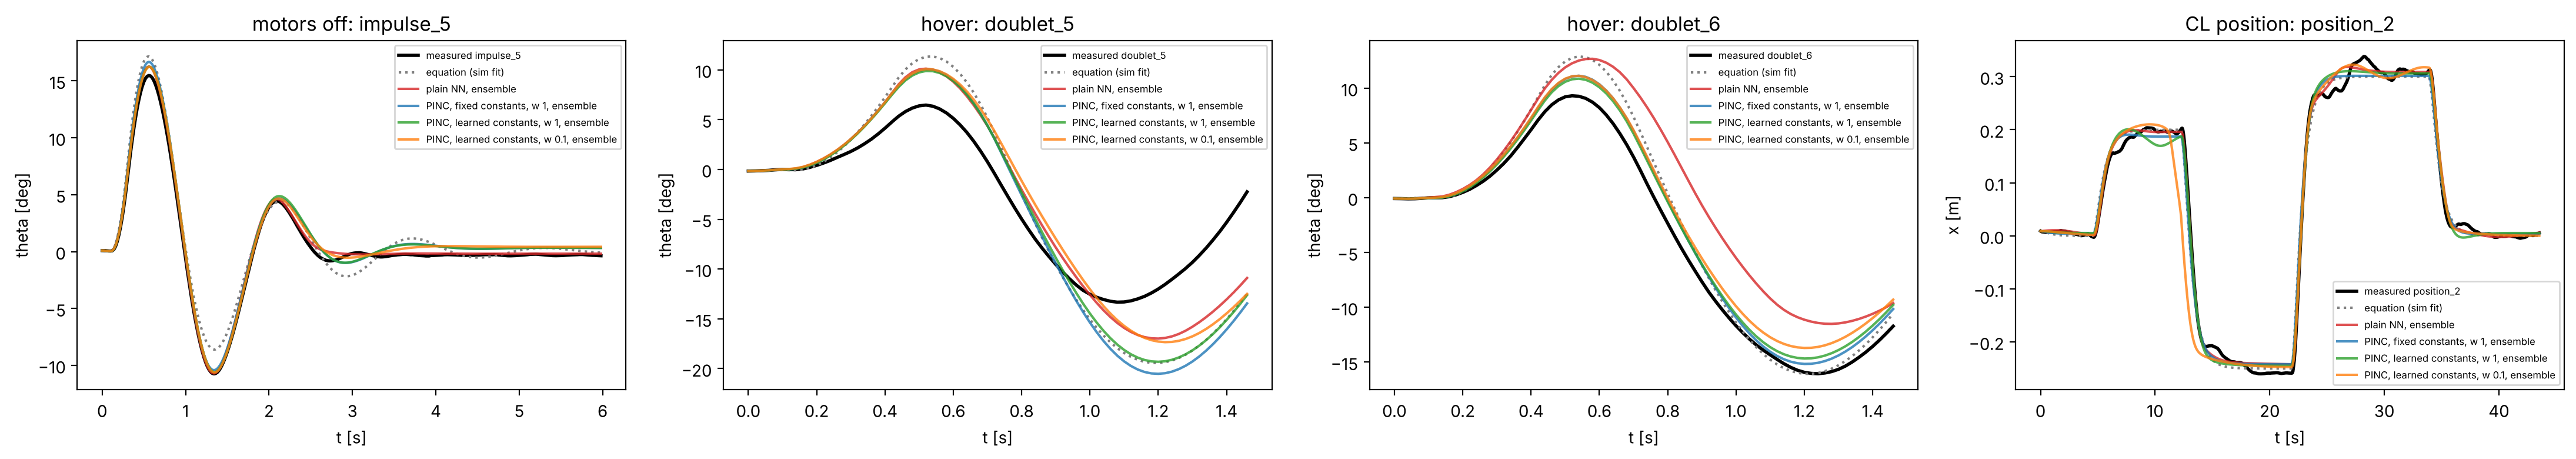

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(22, 4))
tests = [(case, n) for case, c in CASES.items() for n in c['test']]
for a, (case, n) in zip(ax, tests):
    c = CASES[case]; f = c['F'][n]; k = (lambda z: z) if case == 'CL position' else np.degrees
    a.plot(f.t, k(f.y), 'k', lw=2, label='measured ' + n)
    a.plot(f.t, k(run_ivp(c['P'], f, c)[0]), ':', color='gray', label='equation (sim fit)')
    for (label, _, _), color in zip(VARIANTS, ['C3', 'C0', 'C2', 'C1']):
        a.plot(f.t, k(run_open([r['step'] for r in RUNS[(case, label)]], f)[0]), color=color, alpha=0.8, label=label + ', ensemble')
    a.set(title=f'{case}: {n}', xlabel='t [s]', ylabel='x [m]' if case == 'CL position' else 'theta [deg]'); a.legend(fontsize=6)
plt.tight_layout(); plt.savefig('../figures/batch9_improvements.png', dpi=120, bbox_inches='tight'); plt.show()

## 6. Inverse PINN on position, one fit per setpoint step
Batch 7b fitted one smooth curve NN(t) over a whole 35 s flight; at every setpoint step the acceleration jumps, which a smooth curve cannot follow, so the constants came out low (wn 1.27 vs 2.27). Here each segment between two setpoint changes gets its own fit; the constants are averaged over all segments of the train flights.

In [9]:
def train_inverse_pinn(f, c, seed=0, epochs=20000, lr=1e-3, w_data=3000.0, width=32, scale=0.3):
    torch.manual_seed(seed)
    t_np = f.t.values - f.t.values[0]; T = t_np[-1]
    t_all = col(t_np); r_del = col(np.interp(t_np - c['tau'], t_np, f.r.values)); y_all = col(f.y.values)
    net = mlp(1, 1, width); y_of = lambda t: scale * net(2 * t / T - 1)
    raw = {k: torch.nn.Parameter(torch.tensor(float(np.log(v)))) for k, v in zip(['wn', 'xi'], [3.47, 0.84])}
    consts = lambda: {k: v.exp() for k, v in raw.items()}
    opt = torch.optim.Adam(list(net.parameters()) + list(raw.values()), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs, eta_min=lr / 20)
    for e in range(epochs):
        t = t_all.clone().requires_grad_(True); y = y_of(t)
        yd = torch.autograd.grad(y, t, torch.ones_like(y), create_graph=True)[0]
        ydd = torch.autograd.grad(yd, t, torch.ones_like(yd), create_graph=True)[0]
        physics = (((ydd - accel_cl(y, yd, r_del, consts())) / scale)**2).mean()
        data = (((y - y_all) / scale)**2).mean()
        loss = physics + w_data * data
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return {k: float(v.detach()) for k, v in consts().items()}

c = CASES['CL position']; segs = []
for n in c['train']:
    f = c['F'][n]; ch = np.flatnonzero(np.abs(np.diff(f.r.values)) > 1e-3) + 1      # setpoint changes
    edges = [0] + list(ch) + [len(f)]
    for i0, i1 in zip(edges[:-1], edges[1:]):
        if (i1 - i0) * DT < 2: continue
        s = f.iloc[max(i0 - 5, 0):i1].reset_index(drop=True)                        # 0.1 s before the change
        t0 = time.time(); p = train_inverse_pinn(s, c); segs.append(dict(flight=n, start_s=round(s.t[0], 1), length_s=round(s.t.iloc[-1] - s.t[0], 1), **p))
        print(segs[-1], f'({time.time() - t0:.0f} s)')
S = pd.DataFrame(segs); pseg = dict(wn=S.wn.mean(), xi=S.xi.mean())
f = c['F']['position_2']; Y, V = run_ivp(pseg, f, c)
rows3 = pd.DataFrame([dict(model='inverse PINN, whole flight (Batch 7b)', wn=1.268, xi=0.550, VAF_x=97.0, VAF_v=79.95),
                      dict(model='inverse PINN, one fit per step', wn=pseg['wn'], xi=pseg['xi'], VAF_x=vaf(f.y.values, Y), VAF_v=vaf(f.yd.values, V)),
                      dict(model='simulation fit', wn=c['P']['wn'], xi=c['P']['xi'], VAF_x=vaf(f.y.values, run_ivp(c['P'], f, c)[0]), VAF_v=vaf(f.yd.values, run_ivp(c['P'], f, c)[1]))]).round(3)
S.to_csv('../results/batch9_inverse_pinn_segments.csv', index=False); rows3.to_csv('../results/batch9_inverse_pinn_position.csv', index=False); rows3

{'flight': 'position_1', 'start_s': np.float64(0.0), 'length_s': np.float64(3.9), 'wn': 2.798804759979248, 'xi': 0.04050910472869873} (74 s)


{'flight': 'position_1', 'start_s': np.float64(3.8), 'length_s': np.float64(9.2), 'wn': 0.6708809733390808, 'xi': 0.03179067000746727} (65 s)


{'flight': 'position_1', 'start_s': np.float64(12.9), 'length_s': np.float64(8.4), 'wn': 0.31384536623954773, 'xi': 1.4851723909378052} (57 s)


{'flight': 'position_1', 'start_s': np.float64(21.2), 'length_s': np.float64(9.8), 'wn': 1.587547779083252, 'xi': 0.7233062386512756} (58 s)


{'flight': 'position_1', 'start_s': np.float64(31.0), 'length_s': np.float64(7.5), 'wn': 1.6181849241256714, 'xi': 0.7698746919631958} (54 s)


{'flight': 'position_3', 'start_s': np.float64(0.0), 'length_s': np.float64(4.4), 'wn': 0.43860986828804016, 'xi': 0.09690561890602112} (49 s)


{'flight': 'position_3', 'start_s': np.float64(4.3), 'length_s': np.float64(6.1), 'wn': 1.7380839586257935, 'xi': 0.8349037170410156} (58 s)


{'flight': 'position_3', 'start_s': np.float64(10.3), 'length_s': np.float64(7.2), 'wn': 1.6158225536346436, 'xi': 0.761801540851593} (75 s)


{'flight': 'position_3', 'start_s': np.float64(17.3), 'length_s': np.float64(8.7), 'wn': 1.6494760513305664, 'xi': 0.7338181138038635} (63 s)


{'flight': 'position_3', 'start_s': np.float64(25.9), 'length_s': np.float64(5.4), 'wn': 1.6279796361923218, 'xi': 0.7865902781486511} (54 s)


,model,wn,xi,VAF_x,VAF_v
0,"inverse PINN, whole flight (Batch 7b)",1.268,0.550,97.000,79.950
1,"inverse PINN, one fit per step",1.406,0.626,98.206,88.706
2,simulation fit,2.249,1.127,99.281,91.709


## 7. Better equations
**a. sin(theta) for pitch** (1-DOF simulation fit, linear vs sin). **b. Friction and level offset for Amr's x model**: v' = -cbar v - kbar (theta - theta_b) - Fc tanh(v / 0.01), fitted on speed like Amr (train velocity_doublet_2, 3, position_1, 3; whole flights).

In [10]:
def accel_1dof_sin(y, yd, r, p):
    return -2 * p['xi'] * p['wn'] * yd - p['wn']**2 * np.sin(y - p['th0']) + p['mu'] * r
rows4 = []
for case in ['motors off', 'hover']:
    c = dict(CASES[case]); c['accel'] = accel_1dof_sin; Ps = sim_fit(c)
    for n in c['test']:
        f = c['F'][n]
        rows4.append(dict(case=case, test=n, VAF_linear=vaf(f.y.values, run_ivp(CASES[case]['P'], f, CASES[case])[0]), VAF_sin=vaf(f.y.values, run_ivp(Ps, f, c)[0]),
                          wn_linear=CASES[case]['P']['wn'], wn_sin=Ps['wn']))
T4 = pd.DataFrame(rows4).round(3); T4.to_csv('../results/batch9_sin_theta.csv', index=False); T4

,case,test,VAF_linear,VAF_sin,wn_linear,wn_sin
0,motors off,impulse_5,96.915,96.897,4.065,4.081
1,hover,doublet_5,44.397,45.154,3.725,3.763
2,hover,doublet_6,97.349,97.345,3.725,3.763


In [11]:
D2 = lambda n: pd.read_csv(f'../data/clean/2dof/{n}.csv').iloc[::5].reset_index(drop=True)
TR2 = ['velocity_doublet_2', 'velocity_doublet_3', 'position_1', 'position_3']; TE2 = ['velocity_doublet_4', 'position_2']
F2 = {n: D2(n) for n in TR2 + TE2}
def sim_x(p, f):
    t, th = f.t.values, f.theta.values
    rhs = lambda tt, z: [z[1], -p['cbar'] * z[1] - p['kbar'] * (np.interp(tt, t, th) - p.get('thb', 0.0)) - p.get('Fc', 0.0) * np.tanh(z[1] / 0.01)]
    return solve_ivp(rhs, (t[0], t[-1]), [f.x[0], f.v[0]], t_eval=t, max_step=DT).y
def fit2(keys, x0, lo, hi):
    res = lambda v: np.concatenate([sim_x(dict(zip(keys, v)), F2[n])[1] - F2[n].v.values for n in TR2])
    return dict(zip(keys, least_squares(res, x0, bounds=(lo, hi)).x))
t0 = time.time()
P_lin = fit2(['kbar', 'cbar'], [4.748, 1.168], [0, 0], [50, 20])
P_fric = fit2(['kbar', 'cbar', 'Fc', 'thb'], [P_lin['kbar'], P_lin['cbar'], 0.01, 0.0], [0, 0, 0, -0.1], [50, 20, 1, 0.1])
print('linear', P_lin, '| friction', P_fric, f'({time.time() - t0:.0f} s)')
rows5 = []
for n in TE2:
    f = F2[n]
    for label, p in [('ANT-X published', dict(kbar=4.748, cbar=1.168)), ('linear fit (Amr)', P_lin), ('friction + level offset', P_fric)]:
        Y = sim_x(p, f); rows5.append(dict(test=n, model=label, VAF_x=vaf(f.x.values, Y[0]), VAF_v=vaf(f.v.values, Y[1]), **{k: round(v, 4) for k, v in p.items()}))
T5 = pd.DataFrame(rows5).round(2); T5.to_csv('../results/batch9_friction_2dof.csv', index=False); T5

linear {'kbar': np.float64(3.3813717725506267), 'cbar': np.float64(1.3450657331346128)} | friction {'kbar': np.float64(3.5542284430215862), 'cbar': np.float64(0.3459005778235167), 'Fc': np.float64(0.14761329584724606), 'thb': np.float64(-0.005332121008918016)} (36 s)


,test,model,VAF_x,VAF_v,kbar,cbar,Fc,thb
0,velocity_doublet_4,ANT-X published,0.00,82.79,4.75,1.17,NaN,NaN
1,velocity_doublet_4,linear fit (Amr),23.60,86.51,3.38,1.35,NaN,NaN
2,velocity_doublet_4,friction + level offset,56.24,91.51,3.55,0.35,0.15,-0.01
3,position_2,ANT-X published,0.00,9.85,4.75,1.17,NaN,NaN
4,position_2,linear fit (Amr),23.20,60.61,3.38,1.35,NaN,NaN
5,position_2,friction + level offset,90.72,94.97,3.55,0.35,0.15,-0.01


## 8. What this shows
Read the tables above: for each case, compare the PINC variants with the plain NN on the median, the worst seed (seeds_ok) and the ensemble; compare learned constants with the simulation fit; check whether the per-step inverse PINN and the better equations move closer to the measured flights.